In [8]:
import matplotlib.pyplot as plt
import numpy as np
from matplotlib.colors import LinearSegmentedColormap
from PIL import Image

from src.dataloader import get_labels
from src.dataloader_slic import get_train_test_val

business_blue = '#365C7D'
business_gray = '#53606B'
light_gray = '#C4CBD2'

plt.rcParams.update({
    'axes.spines.top': False,
    'axes.spines.right': False,
    'axes.edgecolor': light_gray,
    'axes.labelcolor': business_gray,
    'axes.titlelocation': 'left',
    'axes.titlecolor': '#27333D',
    'axes.titleweight': 'normal',
    'text.color': '#27333D',
    'xtick.color': business_gray,
    'ytick.color': business_gray,
    'xtick.major.size': 0,
    'ytick.major.size': 0,
})

data = get_train_test_val(include_original_masks=False)
split_names = ['train', 'val', 'test']
class_names = get_labels()
class_ids = np.arange(1, len(class_names) + 1)

images = []
masks = []
for split_name in split_names:
    images.extend(data[split_name]['images'])
    masks.extend(data[split_name]['masks'])

print(f'Razem: {len(images)} zdjęć i {len(masks)} masek')

Razem: 606 zdjęć i 606 masek


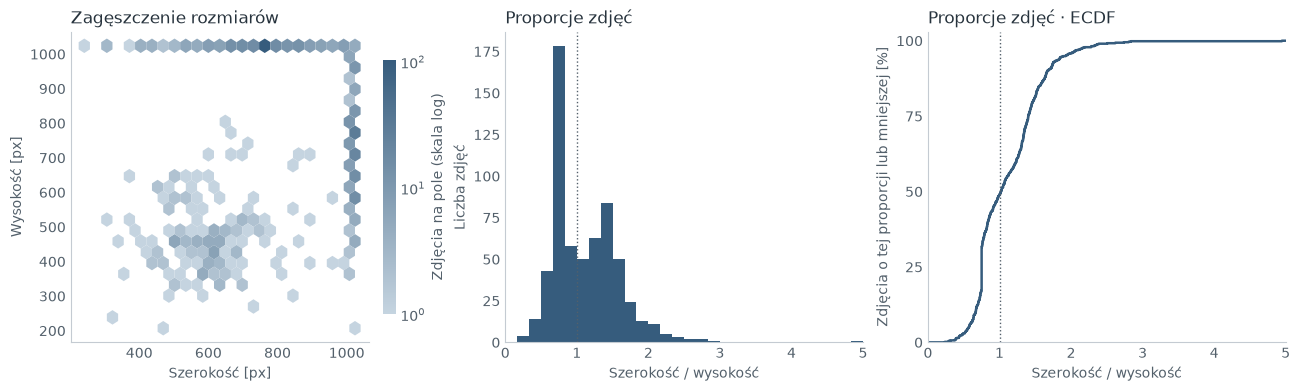

In [9]:
widths = np.array([image.shape[1] for image in images])
heights = np.array([image.shape[0] for image in images])
aspect_ratios = widths / heights

fig, axes = plt.subplots(1, 3, figsize=(13, 3.8), layout='constrained')

density_colors = LinearSegmentedColormap.from_list(
    'business_blues', ['#C5D4E0', business_blue]
)
density = axes[0].hexbin(
    widths, heights, gridsize=24, mincnt=1, bins='log',
    cmap=density_colors, linewidths=0,
)
axes[0].set(xlabel='Szerokość [px]', ylabel='Wysokość [px]', title='Zagęszczenie rozmiarów')
axes[0].set_aspect('equal')
colorbar = fig.colorbar(density, ax=axes[0], shrink=0.82, pad=0.04)
colorbar.set_label('Zdjęcia na pole (skala log)')
colorbar.minorticks_off()
colorbar.outline.set_visible(False)

ratio_limit = np.ceil(aspect_ratios.max())
axes[1].hist(aspect_ratios, bins=30, range=(0, ratio_limit), color=business_blue)
axes[1].set(xlabel='Szerokość / wysokość', ylabel='Liczba zdjęć', title='Proporcje zdjęć')

sorted_ratios = np.sort(aspect_ratios)
cumulative_percent = 100 * np.arange(1, len(sorted_ratios) + 1) / len(sorted_ratios)
axes[2].step(
    np.r_[0, sorted_ratios, ratio_limit], np.r_[0, cumulative_percent, 100],
    where='post', color=business_blue, linewidth=1.8,
)
axes[2].set(
    xlabel='Szerokość / wysokość', ylabel='Zdjęcia o tej proporcji lub mniejszej [%]',
    title='Proporcje zdjęć · ECDF', ylim=(0, 103), yticks=[0, 25, 50, 75, 100],
)

for ax in axes[1:]:
    ax.axvline(1, color=business_gray, linestyle=':', linewidth=1)
    ax.set_xlim(0, ratio_limit)

plt.show()

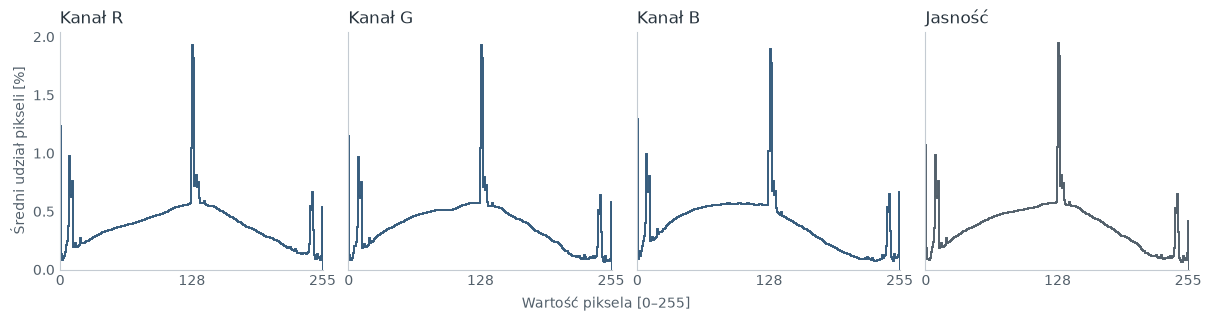

In [10]:
levels = np.arange(256)
bin_edges = np.arange(257) - 0.5
rgb_hist = np.zeros((3, 256))
gray_hist = np.zeros(256)
mean_brightness = []

# Każde zdjęcie ma taki sam wkład w średni histogram.
for image in images:
    rgb = Image.fromarray(image)
    pixel_count = image.shape[0] * image.shape[1]
    rgb_hist += np.array(rgb.histogram()).reshape(3, 256) / pixel_count

    gray_counts = np.array(rgb.convert('L').histogram())
    gray_hist += gray_counts / pixel_count
    mean_brightness.append((gray_counts @ levels) / pixel_count)

rgb_hist *= 100 / len(images)
gray_hist *= 100 / len(images)

fig, axes = plt.subplots(1, 4, figsize=(12, 3.1), sharex=True, sharey=True, layout='constrained')
histograms = [*rgb_hist, gray_hist]
titles = ['Kanał R', 'Kanał G', 'Kanał B', 'Jasność']
colors = [business_blue, business_blue, business_blue, business_gray]

for ax, histogram, title, color in zip(axes, histograms, titles, colors):
    ax.stairs(histogram, bin_edges, color=color, linewidth=1.4)
    ax.set(title=title, xlim=(-0.5, 255.5), xticks=[0, 128, 255])

axes[0].set_ylabel('Średni udział pikseli [%]')
fig.supxlabel('Wartość piksela [0–255]', color=business_gray, fontsize=10)
plt.show()

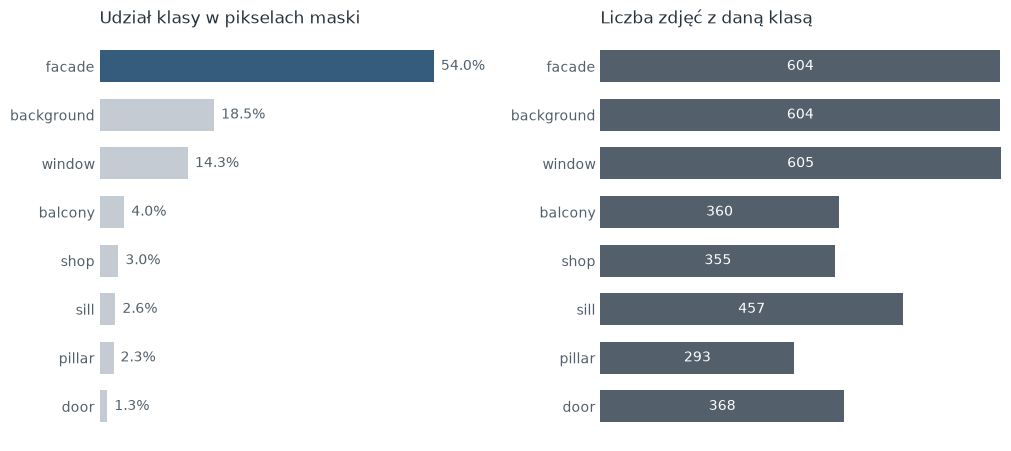

In [14]:
pixels_by_split = {}
images_by_split = {}

for split_name in split_names:
    pixel_counts = np.zeros(len(class_names), dtype=np.int64)
    image_counts = np.zeros(len(class_names), dtype=np.int64)

    for mask in data[split_name]['masks']:
        counts = np.bincount(mask.ravel(), minlength=len(class_names) + 1)
        pixel_counts += counts[class_ids]
        image_counts += counts[class_ids] > 0

    pixels_by_split[split_name] = pixel_counts
    images_by_split[split_name] = image_counts

class_pixels = np.sum(list(pixels_by_split.values()), axis=0)
class_images = np.sum(list(images_by_split.values()), axis=0)
pixel_share = 100 * class_pixels / class_pixels.sum()

class_order = np.argsort(pixel_share)[::-1]
ordered_names = [class_names[index] for index in class_order]
ordered_share = pixel_share[class_order]
ordered_counts = class_images[class_order]

fig, axes = plt.subplots(1, 2, figsize=(10, 4.4), sharey=True, layout='constrained')

share_colors = [business_blue] + [light_gray] * (len(class_names) - 1)
share_bars = axes[0].barh(ordered_names, ordered_share, color=share_colors, height=0.66)
axes[0].bar_label(share_bars, fmt='%.1f%%', padding=5, color=business_gray)
axes[0].set(title='Udział klasy w pikselach maski', xlim=(0, ordered_share.max() * 1.2))

count_bars = axes[1].barh(ordered_names, ordered_counts, color=business_gray, height=0.66)
axes[1].bar_label(count_bars, label_type='center', fmt='%d', color='white')
axes[1].set(title='Liczba zdjęć z daną klasą', xlim=(0, len(images)))
axes[1].tick_params(axis='y', labelleft=True)

for ax in axes:
    ax.spines['left'].set_visible(False)
    ax.spines['bottom'].set_visible(False)
    ax.set_xticks([])

axes[0].invert_yaxis()
plt.show()

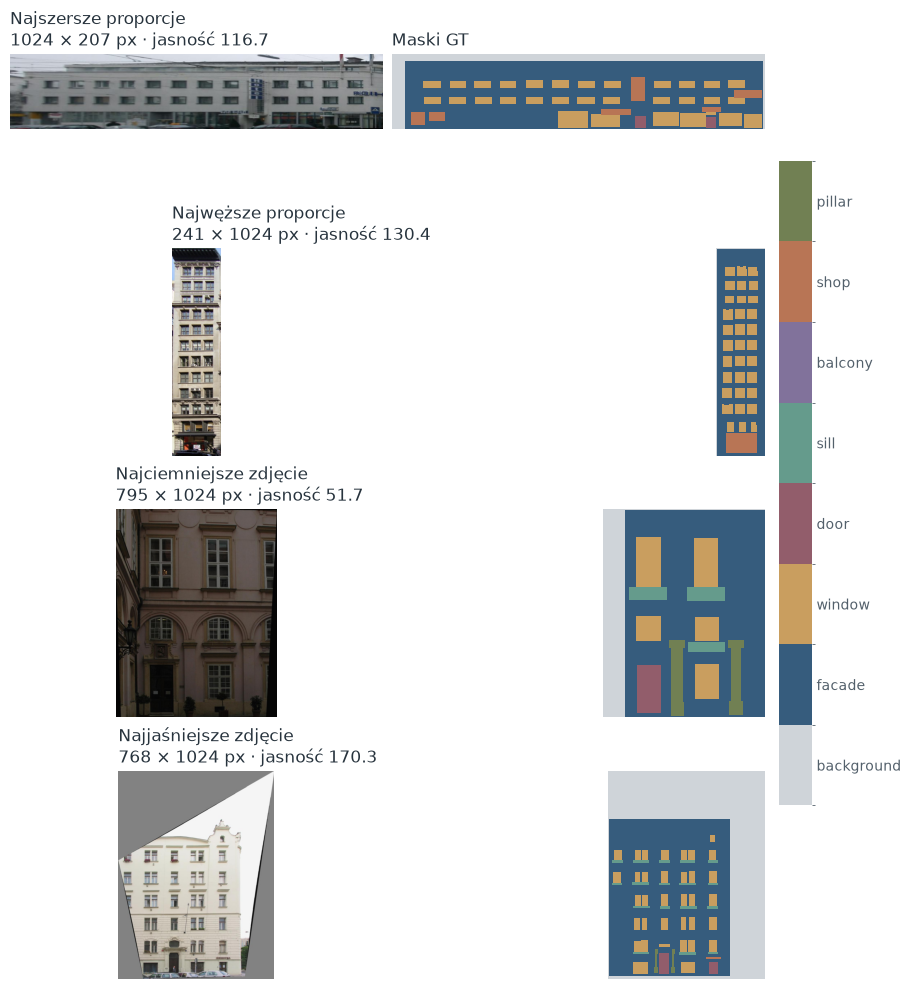

In [15]:
from matplotlib.colors import BoundaryNorm, ListedColormap

examples = [
    ('Najszersze proporcje', np.argmax(aspect_ratios)),
    ('Najwęższe proporcje', np.argmin(aspect_ratios)),
    ('Najciemniejsze zdjęcie', np.argmin(mean_brightness)),
    ('Najjaśniejsze zdjęcie', np.argmax(mean_brightness)),
]

colors = ['#CFD4D9', business_blue, '#C99E5F', '#925D6B', '#659B8C', '#81729B', '#B87555', '#718053']
cmap = ListedColormap(colors)
norm = BoundaryNorm(np.arange(0.5, len(class_names) + 1), cmap.N)
fig, axes = plt.subplots(len(examples), 2, figsize=(9, 10), layout='constrained')

for (title, index), (image_ax, mask_ax) in zip(examples, axes):
    image_ax.imshow(images[index])
    summary = f'{widths[index]} × {heights[index]} px · jasność {mean_brightness[index]:.1f}'
    image_ax.set_title(f'{title}\n{summary}')
    image_ax.axis('off')

    mask_plot = mask_ax.imshow(masks[index], cmap=cmap, norm=norm, interpolation='nearest')
    mask_ax.axis('off')

axes[0, 1].set_title('Maski GT')
colorbar = fig.colorbar(mask_plot, ax=axes[:, 1], ticks=class_ids, shrink=0.65, pad=0.04)
colorbar.set_ticks(class_ids, labels=class_names)
colorbar.outline.set_visible(False)
plt.show()

In [16]:
print('Występowanie klas w podziałach (liczba zdjęć i odsetek)')
print(f"{'':<14}" + ''.join(f'{name:>17}' for name in split_names))

split_sizes = [len(data[name]['images']) for name in split_names]
print(f"{'Wszystkie':<14}" + ''.join(f'{size:>17}' for size in split_sizes))

for class_index in class_order:
    class_name = class_names[class_index]
    row = f'{class_name:<14}'
    for split_name, size in zip(split_names, split_sizes):
        count = images_by_split[split_name][class_index]
        entry = f'{count} ({100 * count / size:.1f}%)'
        row += f'{entry:>17}'
    print(row)

Występowanie klas w podziałach (liczba zdjęć i odsetek)
                          train              val             test
Wszystkie                   424               91               91
facade              423 (99.8%)      91 (100.0%)       90 (98.9%)
background          422 (99.5%)      91 (100.0%)      91 (100.0%)
window              423 (99.8%)      91 (100.0%)      91 (100.0%)
balcony             255 (60.1%)       50 (54.9%)       55 (60.4%)
shop                245 (57.8%)       53 (58.2%)       57 (62.6%)
sill                329 (77.6%)       63 (69.2%)       65 (71.4%)
pillar              208 (49.1%)       40 (44.0%)       45 (49.5%)
door                256 (60.4%)       54 (59.3%)       58 (63.7%)
